## CL-1 Lab Assignment 4 (Group A) : Clustering Analysis
### K-Means Clustering on the Iris Dataset (Elbow Method)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score, v_measure_score, confusion_matrix)
from scipy.optimize import linear_sum_assignment

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

In [2]:
if os.path.exists("Iris.csv"):
    df = pd.read_csv("Iris.csv")
    print("Loaded Iris.csv from disk")
else:
    from sklearn.datasets import load_iris
    iris = load_iris(as_frame=True)
    df = iris.frame.copy()
    df.columns = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "target"]
    df["Species"] = df["target"].map(dict(enumerate(["Iris-setosa", "Iris-versicolor", "Iris-virginica"])))
    df = df.drop(columns="target")
    df.insert(0, "Id", range(1, len(df) + 1))
    print("Iris.csv not found -> using the copy bundled with scikit-learn (same data)")
df.head()

Iris.csv not found -> using the copy bundled with scikit-learn (same data)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print("Shape:", df.shape)
print("\nData types & missing values")
print(pd.concat([df.dtypes.rename("dtype"), df.isnull().sum().rename("missing")], axis=1))
print("\nDuplicate rows (ignoring Id):", df.drop(columns="Id").duplicated().sum())
print("\nSpecies counts:\n", df["Species"].value_counts())

Shape: (150, 6)

Data types & missing values
                 dtype  missing
Id               int64        0
SepalLengthCm  float64        0
SepalWidthCm   float64        0
PetalLengthCm  float64        0
PetalWidthCm   float64        0
Species            str        0

Duplicate rows (ignoring Id): 1

Species counts:
 Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [4]:
df.describe().round(2)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.00,150.00,150.00,150.00,150.00
mean,75.50,5.84,3.06,3.76,1.20
std,43.45,0.83,0.44,1.77,0.76
min,1.00,4.30,2.00,1.00,0.10
25%,38.25,5.10,2.80,1.60,0.30
50%,75.50,5.80,3.00,4.35,1.30
75%,112.75,6.40,3.30,5.10,1.80
max,150.00,7.90,4.40,6.90,2.50


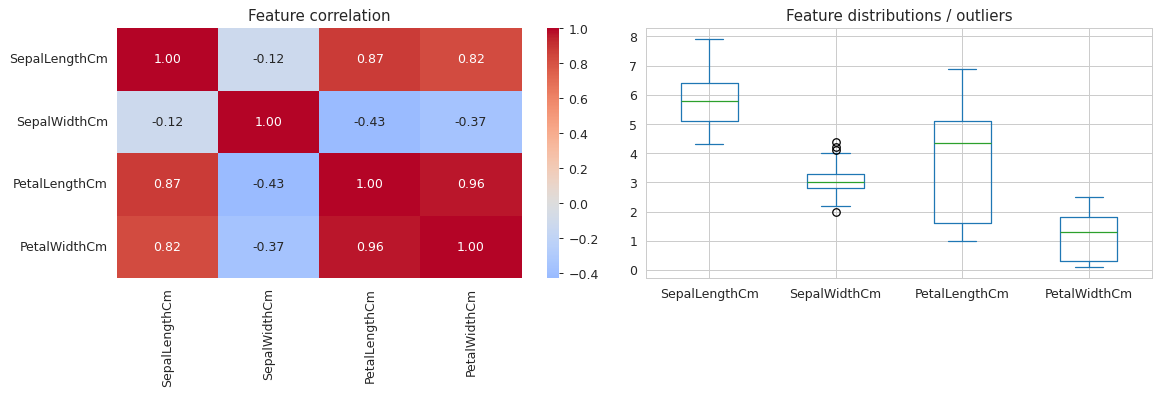

In [5]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=axes[0])
axes[0].set_title("Feature correlation")
df[features].plot(kind="box", ax=axes[1]); axes[1].set_title("Feature distributions / outliers")
plt.tight_layout(); plt.show()

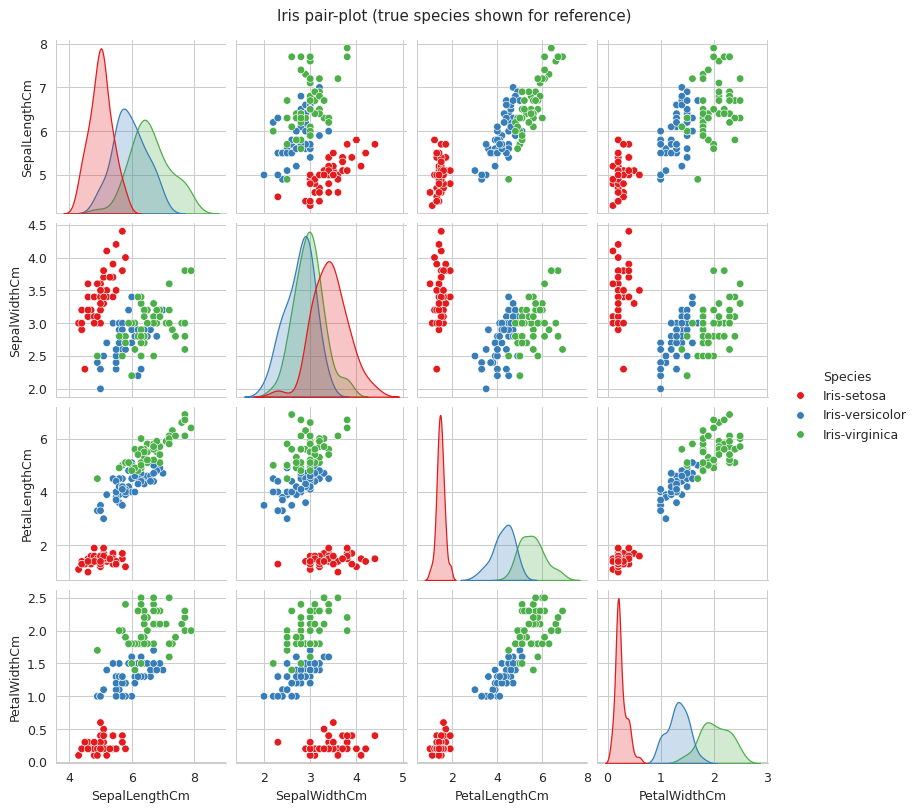

In [6]:
# Pair-plot coloured by the TRUE species (only for our understanding - K-Means will not see this column)
sns.pairplot(df.drop(columns="Id"), hue="Species", palette="Set1", diag_kind="kde", height=2.2)
plt.suptitle("Iris pair-plot (true species shown for reference)", y=1.02)
plt.show()

In [7]:
X = df[features].values
y_true = pd.factorize(df["Species"])[0]          # kept ONLY for evaluation later
species_names = list(pd.factorize(df["Species"])[1])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled means :", X_scaled.mean(axis=0).round(3))
print("Scaled stds  :", X_scaled.std(axis=0).round(3))

Scaled means : [-0. -0. -0. -0.]
Scaled stds  : [1. 1. 1. 1.]


In [ ]:
# Training the Clustring Model
km_sk = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
print(f"scikit-learn    : converged in {km_sk.n_iter_} iterations, WCSS = {km_sk.inertia_:.3f}")

In [ ]:
# Elbow Method to find best "k"
K_RANGE = range(1, 11)
wcss = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    wcss.append(km.inertia_)

elbow_df = pd.DataFrame({"k": list(K_RANGE), "WCSS": wcss})
elbow_df["Drop from previous"] = elbow_df["WCSS"].diff().abs()
elbow_df["% drop"] = (elbow_df["Drop from previous"] / elbow_df["WCSS"].shift(1) * 100)
elbow_df.round(2).set_index("k")

,WCSS,Drop from previous,% drop
k,,,
1,600.00,NaN,NaN
2,222.36,377.64,62.94
3,139.82,82.54,37.12
4,114.09,25.73,18.40
5,90.93,23.17,20.30
6,81.54,9.38,10.32
7,72.63,8.91,10.93
8,62.54,10.09,13.89
9,55.12,7.42,11.87


Elbow (knee) detected at k = 3


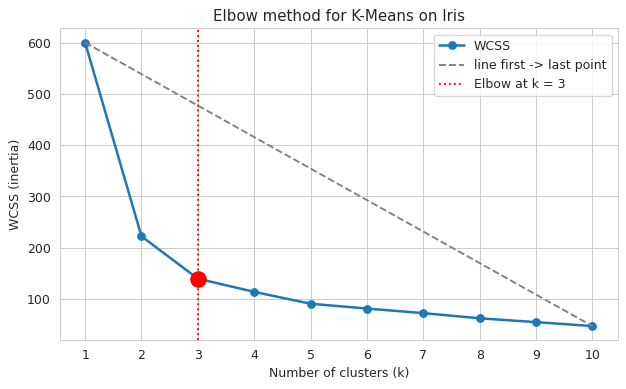

In [10]:
# Automatic "knee" detection: the point farthest from the straight line joining first & last points
pts = np.c_[list(K_RANGE), wcss]
p1, p2 = pts[0], pts[-1]
line = (p2 - p1) / np.linalg.norm(p2 - p1)
vec = pts - p1
dist_to_line = np.abs(vec[:, 0] * line[1] - vec[:, 1] * line[0])
knee_k = int(pts[dist_to_line.argmax(), 0])

plt.figure(figsize=(8, 4.5))
plt.plot(K_RANGE, wcss, "o-", lw=2, label="WCSS")
plt.plot([p1[0], p2[0]], [p1[1], p2[1]], "--", color="gray", label="line first -> last point")
plt.axvline(knee_k, color="red", ls=":", label=f"Elbow at k = {knee_k}")
plt.scatter([knee_k], [wcss[knee_k - 1]], s=150, color="red", zorder=5)
plt.xticks(list(K_RANGE)); plt.xlabel("Number of clusters (k)"); plt.ylabel("WCSS (inertia)")
plt.title("Elbow method for K-Means on Iris"); plt.legend(); plt.show()
print("Elbow (knee) detected at k =", knee_k)

In [ ]:
# Final Model with k = 3 
K = 3
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=20, max_iter=300, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(f"Iterations to converge : {kmeans.n_iter_}")
print(f"WCSS (inertia)         : {kmeans.inertia_:.3f}")
print(f"Silhouette score       : {silhouette_score(X_scaled, df['Cluster']):.3f}")
print("\nCluster sizes:\n", df["Cluster"].value_counts().sort_index())

# centroids back in the ORIGINAL units (cm) so they can be interpreted
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features).round(2)
centroids.index.name = "Cluster"
centroids

Iterations to converge : 4
WCSS (inertia)         : 139.820
Silhouette score       : 0.460

Cluster sizes:
 Cluster
0    53
1    50
2    47
Name: count, dtype: int64


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


In [14]:
# Cluster profile: mean feature values per cluster
df.groupby("Cluster")[features].mean().round(2)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


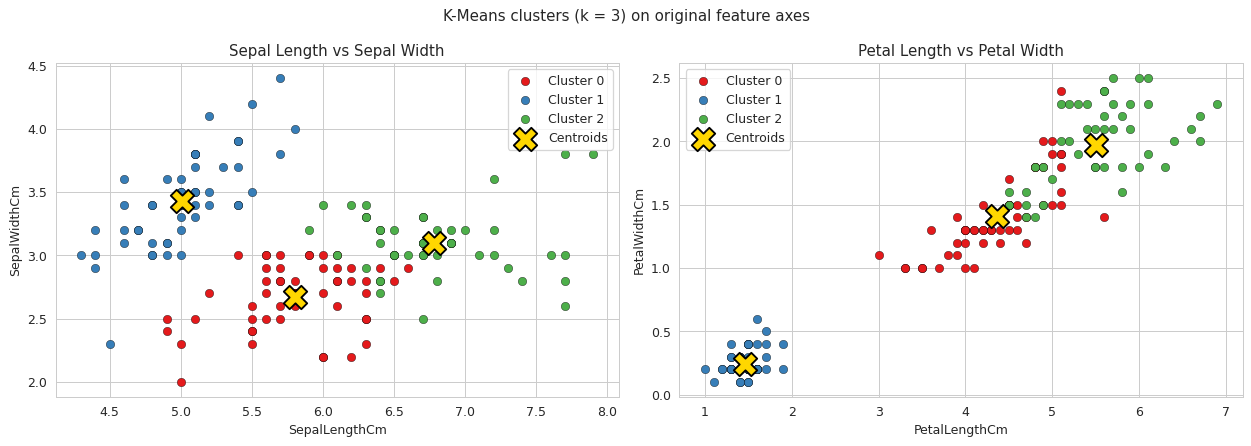

In [ ]:
# Visualizing the cluster
palette = ["#e41a1c", "#377eb8", "#4daf4a"]
cent_orig = scaler.inverse_transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pairs = [(0, 1, "Sepal Length vs Sepal Width"), (2, 3, "Petal Length vs Petal Width")]
for ax, (i, j, title) in zip(axes, pairs):
    for c in range(K):
        m = df["Cluster"] == c
        ax.scatter(X[m, i], X[m, j], s=45, color=palette[c], edgecolor="k", linewidth=0.3, label=f"Cluster {c}")
    ax.scatter(cent_orig[:, i], cent_orig[:, j], marker="X", s=350, c="gold", edgecolor="black", linewidth=1.5, label="Centroids")
    ax.set_xlabel(features[i]); ax.set_ylabel(features[j]); ax.set_title(title); ax.legend()
plt.suptitle("K-Means clusters (k = 3) on original feature axes")
plt.tight_layout(); plt.show()

25 of 150 flowers fall in a 'wrong' cluster - all are versicolor/virginica border cases:


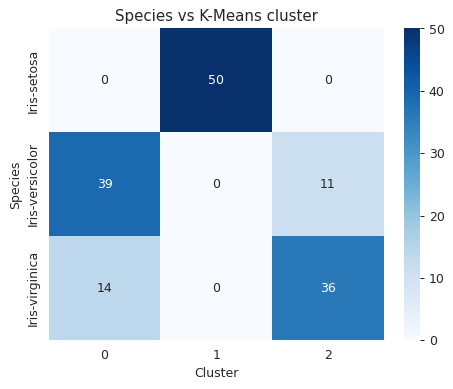

,Id,Species,Cluster,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
50,51,Iris-versicolor,2,7.0,3.2,4.7,1.4
51,52,Iris-versicolor,2,6.4,3.2,4.5,1.5
52,53,Iris-versicolor,2,6.9,3.1,4.9,1.5
56,57,Iris-versicolor,2,6.3,3.3,4.7,1.6
65,66,Iris-versicolor,2,6.7,3.1,4.4,1.4
70,71,Iris-versicolor,2,5.9,3.2,4.8,1.8
75,76,Iris-versicolor,2,6.6,3.0,4.4,1.4
76,77,Iris-versicolor,2,6.8,2.8,4.8,1.4
77,78,Iris-versicolor,2,6.7,3.0,5.0,1.7
85,86,Iris-versicolor,2,6.0,3.4,4.5,1.6


In [19]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Species vs K-Means cluster"); plt.show()

wrong = np.where(mapped != y_true)[0]
print(f"{len(wrong)} of {len(df)} flowers fall in a 'wrong' cluster - all are versicolor/virginica border cases:")
df.iloc[wrong][["Id", "Species", "Cluster"] + features].head(15)